# CerviGrade: Bounding Box Derivation & YOLO Detector Training

CRIC, SIPaKMeD, and Mendeley all ship as single-cell crops with no real bounding box —
CRIC's crop is a fixed 200x200 window around a known nucleus point, SIPaKMeD/Mendeley
have no location information at all. This notebook:

1. Derives a real box for every cropped image (already done once — loaded from a saved
   Kaggle Dataset here instead of re-running the slow part).
2. Splits CRIC and SIPaKMeD into leakage-safe train/val/test sets, grouped by source slide.
3. Converts the split, boxed data into YOLO training format.
4. Trains a YOLO11 detector in two stages: first SIPaKMeD (learn to find a cell), then
   CRIC (learn to grade its severity).
5. Checks the result, both numerically and visually.

This version is cleaned up and reordered to run top-to-bottom without errors — the
original had cells run out of order across many sessions. The slow segmentation step
(CRIC ~5 min, SIPaKMeD ~1.5 min, Mendeley ~63 min) is **not** re-run here; its output
is loaded from the `cervigrade-cell-boxes` Kaggle Dataset instead.

## 1. Locate the datasets

Quick sanity check that the three raw datasets (CRIC_cropped, Mendeley, SIPaKMeD) are
still attached as Kaggle Inputs on this session. Not strictly needed to load the saved
box CSVs below, but if any of these come back `None`, something's wrong with the
attached inputs before anything else is worth running.

In [1]:
import os

def find_all_dirs(root, predicate):
    """Walk `root` and return every directory path whose name/contents satisfy `predicate`."""
    matches = []
    for dirpath, dirnames, filenames in os.walk(root):
        if predicate(os.path.basename(dirpath), dirnames, filenames):
            matches.append(dirpath)
    return matches

KAGGLE_INPUT = "/kaggle/input"

# CRIC: folder is literally named CRIC_cropped and directly holds class subfolders
cric_matches = find_all_dirs(KAGGLE_INPUT, lambda name, dirnames, filenames: name == "CRIC_cropped")
CRIC_CROPPED_DIR = cric_matches[0] if cric_matches else None

# Mendeley: search case-insensitively for "mendeley" anywhere in the folder name
mendeley_matches = find_all_dirs(KAGGLE_INPUT, lambda name, dirnames, filenames: "mendeley" in name.lower())
MENDELEY_ROOT = mendeley_matches[0] if mendeley_matches else None

# SIPaKMeD: collect EVERY folder that directly contains a "CROPPED" subfolder
sipakmed_cropped_parents = find_all_dirs(KAGGLE_INPUT, lambda name, dirnames, filenames: "CROPPED" in dirnames)
SIPAKMED_CLASS_DIRS = {os.path.basename(p).replace("im_", ""): os.path.join(p, "CROPPED")
                        for p in sipakmed_cropped_parents}

print("CRIC:", CRIC_CROPPED_DIR)
print("Mendeley:", MENDELEY_ROOT)
print("SIPaKMeD classes found:", SIPAKMED_CLASS_DIRS)

CRIC: /kaggle/input/datasets/wagnermushayija/cervigrade-cric-dataset/CRIC_cropped
Mendeley: /kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer
SIPaKMeD classes found: {'Parabasal': '/kaggle/input/datasets/marinaeplissiti/sipakmed/im_Parabasal/im_Parabasal/CROPPED', 'Dyskeratotic': '/kaggle/input/datasets/marinaeplissiti/sipakmed/im_Dyskeratotic/im_Dyskeratotic/CROPPED', 'Metaplastic': '/kaggle/input/datasets/marinaeplissiti/sipakmed/im_Metaplastic/im_Metaplastic/CROPPED', 'Superficial-Intermediate': '/kaggle/input/datasets/marinaeplissiti/sipakmed/im_Superficial-Intermediate/im_Superficial-Intermediate/CROPPED', 'Koilocytotic': '/kaggle/input/datasets/marinaeplissiti/sipakmed/im_Koilocytotic/im_Koilocytotic/CROPPED'}


## 2. How a box was found inside each crop (reference — already run)

For each cropped image: convert to grayscale, separate cell from background with Otsu
thresholding, then split touching/clustered cells apart with watershed segmentation
(distance transform + peak-finding + marker-based splitting) before taking the piece of
the mask nearest the center of the crop as the cell. This function is kept here for
reference and in case the dataset ever needs to be regenerated — the actual run below
loads the already-computed result instead of calling it.

In [2]:
import cv2
import numpy as np
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

def find_cell_bbox_in_crop(image_path, pad=3, max_box_frac=0.85):
    img = cv2.imread(image_path)
    if img is None:
        return None
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask_bool = mask > 0
    if not mask_bool.any():
        return None

    # Split touching cells apart instead of treating one connected
    # blob as a single object: distance transform + watershed.
    distance = ndi.distance_transform_edt(mask_bool)
    coords = peak_local_max(distance, min_distance=15, labels=mask_bool)
    peak_mask = np.zeros_like(distance, dtype=bool)
    peak_mask[tuple(coords.T)] = True
    markers, _ = ndi.label(peak_mask)
    labels = watershed(-distance, markers, mask=mask_bool)

    center_y, center_x = h // 2, w // 2
    target_label = labels[center_y, center_x]

    if target_label == 0:
        present = [l for l in np.unique(labels) if l != 0]
        if not present:
            return None
        best_label, best_dist = None, None
        for l in present:
            ys, xs = np.where(labels == l)
            d = (ys.mean() - center_y) ** 2 + (xs.mean() - center_x) ** 2
            if best_dist is None or d < best_dist:
                best_dist, best_label = d, l
        target_label = best_label

    ys, xs = np.where(labels == target_label)
    if len(xs) == 0:
        return None
    x_min, x_max = max(0, xs.min() - pad), min(w, xs.max() + pad)
    y_min, y_max = max(0, ys.min() - pad), min(h, ys.max() + pad)

    if ((x_max - x_min) * (y_max - y_min)) / (w * h) > max_box_frac:
        return None  # still basically the whole image - treat as a failure, not a box

    return (x_min, y_min, x_max, y_max)

## 3. Running it across all three datasets (reference — already run, DO NOT re-run)

`derive_boxes()` applies the function above to every image and flags anything where it
failed to find a sensible box. Already run once, taking CRIC ~5 min, SIPaKMeD ~1.5 min,
and Mendeley ~63 min (slow because Mendeley's images turned out to be full microscope
fields, not single-cell crops — see the note after the CSV load below).

The cell below is commented out on purpose. Only uncomment and run it if the box data
ever needs to be regenerated from scratch (e.g. new images added to a dataset) —
otherwise skip straight to the next cell, which loads the already-saved result.

In [3]:
import pandas as pd
from tqdm import tqdm

def classdirs_from_root(root_dir, label_map=None):
    out = {}
    for cls in sorted(os.listdir(root_dir)):
        cls_path = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        label = label_map[cls] if label_map else cls
        out[label] = cls_path
    return out

def derive_boxes(class_dirs, dataset_name, min_box_frac=0.05):
    rows = []
    all_files = [(cls, os.path.join(cls_dir, fname))
                 for cls, cls_dir in class_dirs.items()
                 for fname in os.listdir(cls_dir)
                 if fname.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))]
    for cls, fpath in tqdm(all_files, desc=dataset_name):
        img = cv2.imread(fpath)
        if img is None:
            continue
        h, w = img.shape[:2]
        box = find_cell_bbox_in_crop(fpath)
        if box is None:
            rows.append({"filepath": fpath, "label": cls, "dataset": dataset_name,
                         "x_min": None, "y_min": None, "x_max": None, "y_max": None,
                         "ok": False})
            continue
        x_min, y_min, x_max, y_max = box
        box_area_frac = ((x_max - x_min) * (y_max - y_min)) / (w * h)
        ok = box_area_frac >= min_box_frac
        rows.append({"filepath": fpath, "label": cls, "dataset": dataset_name,
                     "x_min": x_min, "y_min": y_min, "x_max": x_max, "y_max": y_max,
                     "ok": ok})
    return pd.DataFrame(rows)

# --- Uncomment only to regenerate from scratch (~70 minutes total) ---
# MENDELEY_LABEL_MAP = {
#     'Negative for Intraepithelial malignancy': 'Negative',
#     'High squamous intra-epithelial lesion': 'HSIL',
#     'Low squamous intra-epithelial lesion': 'LSIL',
#     'Squamous cell carcinoma': 'SCC',
# }
# CRIC_CLASS_DIRS = classdirs_from_root(CRIC_CROPPED_DIR)
# MENDELEY_CLASS_DIRS = classdirs_from_root(MENDELEY_ROOT, MENDELEY_LABEL_MAP)
#
# cric_boxes = derive_boxes(CRIC_CLASS_DIRS, "CRIC")
# mendeley_boxes = derive_boxes(MENDELEY_CLASS_DIRS, "Mendeley")
# sipakmed_boxes = derive_boxes(SIPAKMED_CLASS_DIRS, "SIPaKMeD")
#
# for name, df in [("CRIC", cric_boxes), ("Mendeley", mendeley_boxes), ("SIPaKMeD", sipakmed_boxes)]:
#     total = len(df)
#     failed = (~df["ok"]).sum()
#     print(f"{name}: {total} images, {failed} flagged ({failed/total:.1%})")
#
# cric_boxes.to_csv("/kaggle/working/cric_boxes.csv", index=False)
# mendeley_boxes.to_csv("/kaggle/working/mendeley_boxes.csv", index=False)
# sipakmed_boxes.to_csv("/kaggle/working/sipakmed_boxes.csv", index=False)
# print("Saved -- remember to also publish /kaggle/working/*.csv as a new Kaggle Dataset version.")

## 4. Load the already-derived boxes

Loads the three CSVs from the `cervigrade-cell-boxes` Kaggle Dataset (make sure it's
attached as an Input on this notebook). The path is found by searching rather than
hardcoded, since the exact mount path isn't predictable session to session.

In [4]:
import pandas as pd

boxes_dir = None
for dirpath, dirnames, filenames in os.walk("/kaggle/input"):
    if "cric_boxes.csv" in filenames:
        boxes_dir = dirpath
        break

if boxes_dir is None:
    raise FileNotFoundError(
        "Couldn't find cric_boxes.csv under /kaggle/input -- "
        "make sure the cervigrade-cell-boxes dataset is attached as an Input."
    )

print("Found box CSVs in:", boxes_dir)
cric_boxes = pd.read_csv(os.path.join(boxes_dir, "cric_boxes.csv"))
mendeley_boxes = pd.read_csv(os.path.join(boxes_dir, "mendeley_boxes.csv"))
sipakmed_boxes = pd.read_csv(os.path.join(boxes_dir, "sipakmed_boxes.csv"))

for name, df in [("CRIC", cric_boxes), ("Mendeley", mendeley_boxes), ("SIPaKMeD", sipakmed_boxes)]:
    print(f"{name}: {len(df)} rows, {(~df['ok']).sum()} flagged")

Found box CSVs in: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes
CRIC: 11534 rows, 2590 flagged
Mendeley: 962 rows, 951 flagged
SIPaKMeD: 4049 rows, 1007 flagged


## 5. Visual spot-check

Numbers alone only confirm a box is a plausible size, not that it's actually right.
This draws the derived box on a random sample of images per class so you can judge by
eye whether it's genuinely wrapping the cell.

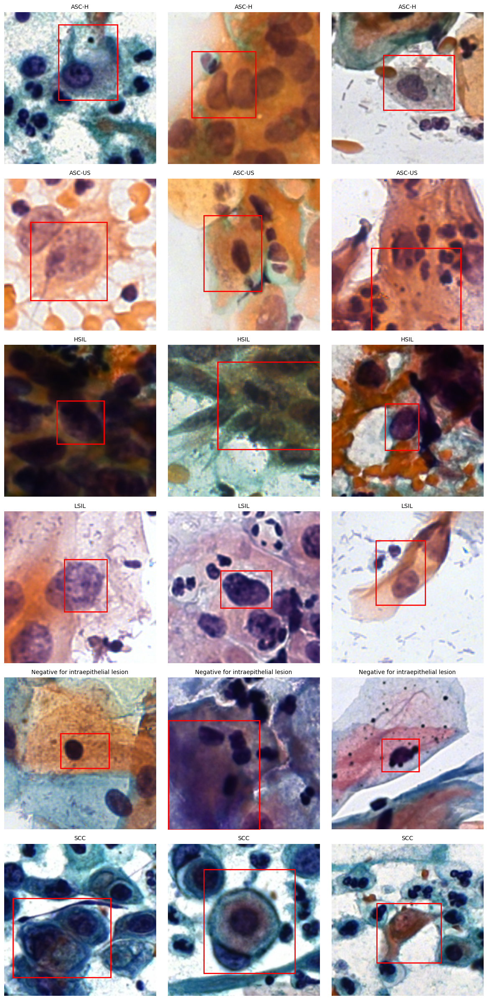

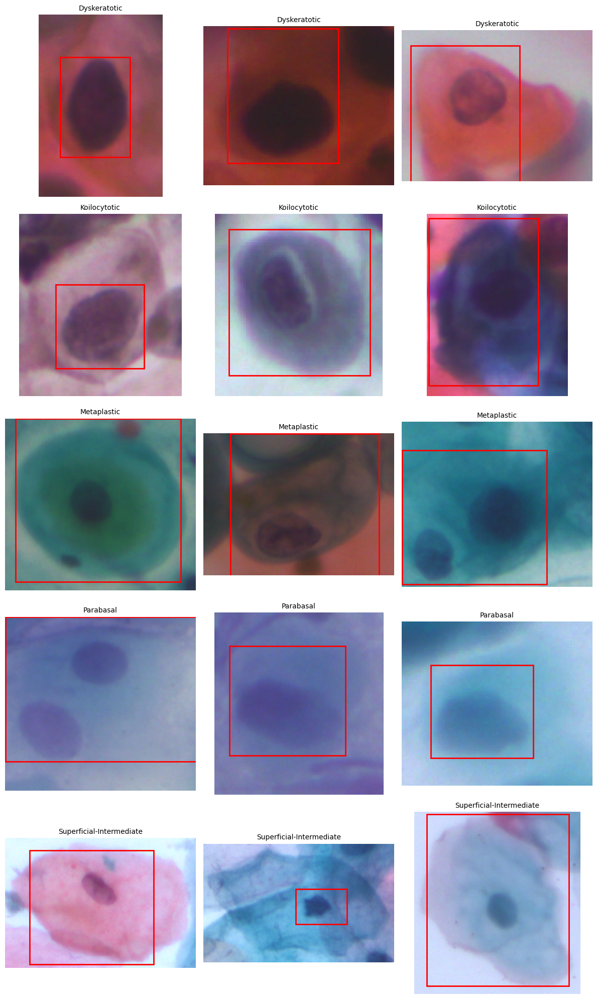

In [5]:
import matplotlib.pyplot as plt

def show_sample_boxes(df, dataset_name, n_per_class=3, seed=42):
    classes = sorted(df["label"].unique())
    fig, axes = plt.subplots(len(classes), n_per_class, figsize=(4 * n_per_class, 4 * len(classes)))
    if len(classes) == 1:
        axes = [axes]
    for row_idx, cls in enumerate(classes):
        sub = df[(df["label"] == cls) & (df["ok"])]
        sample = sub.sample(min(n_per_class, len(sub)), random_state=seed)
        for col_idx, (_, r) in enumerate(sample.iterrows()):
            img = cv2.cvtColor(cv2.imread(r["filepath"]), cv2.COLOR_BGR2RGB)
            ax = axes[row_idx][col_idx] if n_per_class > 1 else axes[row_idx]
            ax.imshow(img)
            ax.add_patch(plt.Rectangle((r["x_min"], r["y_min"]),
                                        r["x_max"] - r["x_min"], r["y_max"] - r["y_min"],
                                        fill=False, edgecolor="red", linewidth=2))
            ax.set_title(cls, fontsize=10)
            ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/box_check_{dataset_name}.png")
    plt.show()

show_sample_boxes(cric_boxes, "CRIC")
show_sample_boxes(sipakmed_boxes, "SIPaKMeD")

**Mendeley is not spot-checked above** — an earlier run found its images are full
microscope fields (1536x2048 px, many scattered cells) rather than single-cell crops
like CRIC/SIPaKMeD, so a derived "box" there doesn't mean the same thing. That's also
why Mendeley isn't used to train this detector (no per-cell coordinates exist to train
or test against) — it's repurposed later as an end-to-end pipeline test instead: run
the trained detector on a Mendeley field image, grade every cell it finds, take the
worst grade as the field's predicted verdict, and compare that to Mendeley's already-
known field-level label.

## 6. Leakage-safe train/val/test split

Split by original source slide/photo (extracted from the filename), not by individual
crop — otherwise cells from the same slide could end up split across train and test,
letting the model "cheat" by recognizing the slide rather than the cell. CRIC's groups
can mix multiple severity classes on one slide, so it's split globally; SIPaKMeD's
groups already align with one class, so it's split per class.

In [6]:
import random

def allocate_group_counts(n, train_frac=0.7, val_frac=0.15, test_frac=0.15):
    if n == 1:
        return 1, 0, 0
    if n == 2:
        return 1, 0, 1
    n_test = max(1, round(n * test_frac))
    n_val = max(1, round(n * val_frac)) if n - n_test >= 2 else 0
    n_train = n - n_test - n_val
    if n_train < 1:
        n_train = 1
        if n_val > 0:
            n_val -= 1
        else:
            n_test -= 1
    return n_train, n_val, n_test

def split_by_group_per_class(df, seed=42):
    rng = random.Random(seed)
    group_split = {}
    for label, sub in df.groupby("label"):
        groups = sorted(sub["group"].unique())
        rng.shuffle(groups)
        n_train, n_val, n_test = allocate_group_counts(len(groups))
        for g in groups[:n_train]: group_split[g] = "train"
        for g in groups[n_train:n_train + n_val]: group_split[g] = "val"
        for g in groups[n_train + n_val:n_train + n_val + n_test]: group_split[g] = "test"
    return df["group"].map(group_split)

def split_by_group_global(df, seed=42, train_frac=0.7, val_frac=0.15):
    rng = random.Random(seed)
    groups = sorted(df["group"].unique())
    rng.shuffle(groups)
    n = len(groups)
    n_train, n_val = round(n * train_frac), round(n * val_frac)
    group_split = {}
    for g in groups[:n_train]: group_split[g] = "train"
    for g in groups[n_train:n_train + n_val]: group_split[g] = "val"
    for g in groups[n_train + n_val:]: group_split[g] = "test"
    return df["group"].map(group_split)

cric_boxes["group"] = cric_boxes["filepath"].apply(lambda p: os.path.basename(p).split("_")[0])
sipakmed_boxes["group"] = sipakmed_boxes["filepath"].apply(lambda p: os.path.basename(p).split("_")[0])

cric_boxes["split"] = split_by_group_global(cric_boxes)
sipakmed_boxes["split"] = split_by_group_per_class(sipakmed_boxes)

for name, df in [("CRIC", cric_boxes), ("SIPaKMeD", sipakmed_boxes)]:
    print(f"\n{name}:")
    print(df[df["ok"]].groupby(["label", "split"]).size().unstack(fill_value=0))

cric_boxes.to_csv("/kaggle/working/cric_boxes.csv", index=False)
sipakmed_boxes.to_csv("/kaggle/working/sipakmed_boxes.csv", index=False)


CRIC:
split                                test  train  val
label                                                
ASC-H                                  46    619  217
ASC-US                                101    383   68
HSIL                                  376    809  344
LSIL                                  118   1016  135
Negative for intraepithelial lesion   661   3281  616
SCC                                    33     98   23

SIPaKMeD:
split                     test  train  val
label                                     
Dyskeratotic                68    435   97
Koilocytotic                69    486  113
Metaplastic                 59    353   83
Parabasal                  122    511  124
Superficial-Intermediate    79    373   70


## 7. Convert to YOLO training format

YOLO needs each box as a center point plus width/height, all as fractions of the image
size (0-1), plus a class number -- and wants images/labels organized into matching
`images/{train,val,test}` and `labels/{train,val,test}` folders.

SIPaKMeD collapses to a single `cell` class (id 0) since it has no severity labels --
it only teaches the detector where cells are. CRIC keeps its real 6 severity classes.

The filename for each written file includes the class label (`safe_label`), not just
the original filename -- SIPaKMeD's five class folders turned out to reuse overlapping
original filenames across classes (since multiple cell types can come from the same
source slide), which silently overwrote files and lost ~43% of SIPaKMeD's images the
first time this ran without the label in the name. Confirmed fixed: with the label
included, SIPaKMeD's write produced exactly the expected 2158/487/397 train/val/test
counts, matching the split table above to the file.

In [7]:
import shutil
from tqdm import tqdm

def write_yolo_dataset(df, out_root, class_to_id, dataset_name):
    df = df[df["ok"] == True]
    for split in ["train", "val", "test"]:
        os.makedirs(os.path.join(out_root, "images", split), exist_ok=True)
        os.makedirs(os.path.join(out_root, "labels", split), exist_ok=True)
    skipped = 0
    for _, r in tqdm(df.iterrows(), total=len(df), desc=dataset_name):
        img = cv2.imread(r["filepath"])
        if img is None:
            skipped += 1
            continue
        h, w = img.shape[:2]
        x_center = (r["x_min"] + r["x_max"]) / 2 / w
        y_center = (r["y_min"] + r["y_max"]) / 2 / h
        box_w = (r["x_max"] - r["x_min"]) / w
        box_h = (r["y_max"] - r["y_min"]) / h
        class_id = class_to_id[r["label"]]

        split = r["split"]
        safe_label = str(r["label"]).replace(" ", "_")
        stem = f"{dataset_name}_{safe_label}_{os.path.splitext(os.path.basename(r['filepath']))[0]}_d{r.get('dup', 0)}"
        cv2.imwrite(os.path.join(out_root, "images", split, stem + ".jpg"), img)
        with open(os.path.join(out_root, "labels", split, stem + ".txt"), "w") as f:
            f.write(f"{class_id} {x_center:.6f} {y_center:.6f} {box_w:.6f} {box_h:.6f}\n")
    print(f"{dataset_name}: wrote {len(df) - skipped} images, skipped {skipped}")

shutil.rmtree("/kaggle/working/yolo_sipakmed", ignore_errors=True)
shutil.rmtree("/kaggle/working/yolo_cric", ignore_errors=True)

sipakmed_class_to_id = {cls: 0 for cls in sipakmed_boxes["label"].unique()}
write_yolo_dataset(sipakmed_boxes, "/kaggle/working/yolo_sipakmed", sipakmed_class_to_id, "sipakmed")

cric_classes = sorted(cric_boxes["label"].unique())
cric_class_to_id = {cls: i for i, cls in enumerate(cric_classes)}
print("CRIC class mapping:", cric_class_to_id)
write_yolo_dataset(cric_boxes, "/kaggle/working/yolo_cric", cric_class_to_id, "cric")

sipakmed: 100%|██████████| 3042/3042 [00:24<00:00, 126.31it/s]


sipakmed: wrote 3042 images, skipped 0
CRIC class mapping: {'ASC-H': 0, 'ASC-US': 1, 'HSIL': 2, 'LSIL': 3, 'Negative for intraepithelial lesion': 4, 'SCC': 5}


cric: 100%|██████████| 8944/8944 [01:17<00:00, 115.75it/s]

cric: wrote 8944 images, skipped 0


In [8]:
for split in ["train", "val", "test"]:
    n = len(os.listdir(f"/kaggle/working/yolo_sipakmed/images/{split}"))
    print(f"sipakmed {split}: {n} files")
for split in ["train", "val", "test"]:
    n = len(os.listdir(f"/kaggle/working/yolo_cric/images/{split}"))
    print(f"cric {split}: {n} files")

# Expect: sipakmed train~2158/val~487/test~397, cric train~6206/val~1403/test~1335
# (matches the split table in section 6 exactly)

sipakmed train: 2158 files
sipakmed val: 487 files
sipakmed test: 397 files
cric train: 6206 files
cric val: 1403 files
cric test: 1335 files


## 8. YOLO dataset config files

In [9]:
import yaml

sipakmed_yaml = {
    "path": "/kaggle/working/yolo_sipakmed",
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "cell"},
}
with open("/kaggle/working/sipakmed.yaml", "w") as f:
    yaml.dump(sipakmed_yaml, f)

cric_yaml = {
    "path": "/kaggle/working/yolo_cric",
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {v: k for k, v in cric_class_to_id.items()},
}
with open("/kaggle/working/cric.yaml", "w") as f:
    yaml.dump(cric_yaml, f)

print(sipakmed_yaml)
print(cric_yaml)

{'path': '/kaggle/working/yolo_sipakmed', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'cell'}}
{'path': '/kaggle/working/yolo_cric', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'ASC-H', 1: 'ASC-US', 2: 'HSIL', 3: 'LSIL', 4: 'Negative for intraepithelial lesion', 5: 'SCC'}}


In [10]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 962.4 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 3.0 MB/s eta 0:00:00


## 9. Stage 1: teach it to find a cell (SIPaKMeD)

Trains YOLO11n (smallest/fastest YOLO11 variant -- appropriate given these are only a
few thousand images, a bigger model would likely just overfit) on SIPaKMeD's single
`cell` class. This is a warm-start, same idea as the "teach cells, then teach severity"
pattern used for the classifiers earlier in this project.

In [11]:
from tqdm.notebook import tqdm
from ultralytics import YOLO

EPOCHS = 30
pbar = tqdm(total=EPOCHS, desc="Stage 1 training")

def on_epoch_end(trainer):
    pbar.update(1)

model = YOLO("yolo11n.pt")
model.add_callback("on_train_epoch_end", on_epoch_end)
model.train(
    data="/kaggle/working/sipakmed.yaml",
    epochs=EPOCHS,
    imgsz=224,
    project="/kaggle/working/runs",
    name="stage1_cellfinder",
)
pbar.close()

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Stage 1 training:   0%|          | 0/30 [00:00<?, ?it/s]

Ultralytics 8.4.171 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/sipakmed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=stage1_cellfinder, nbs=64, nms=None, opset=None, optimize=Fa

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30     0.457G      1.527      1.602      1.567         33        224: 100% ━━━━━━━━━━━━ 135/135 13.7it/s 9.9s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 9.9it/s 1.6s0.1s
                   all        487        487      0.641      0.522      0.587      0.255

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30     0.457G      1.459      1.543      1.535         39        224: 100% ━━━━━━━━━━━━ 135/135 14.6it/s 9.2s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 10.3it/s 1.6s.2s
                   all        487        487      0.616      0.671      0.644       0.28

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30     0.457G       1.45      1.495      1.531         29        224: 100% ━━━━━━━━━━━━ 135/135 14.3it/s 9.4s0.1s
                 Class     Images

**Result (confirmed run):** precision 0.852, recall 0.821, mAP50 0.892, mAP50-95
0.575 -- solid first pass at "where is the cell," ready to build severity grading on
top of.

## 10. Stage 2: teach it severity (CRIC)

Continues training from stage 1's weights instead of generic pretrained ones, swapping
in a fresh 6-class head (Ultralytics does this automatically -- watch for an
"Overriding... nc=1 with nc=6" line, and most of the backbone weights transfer over
since it's not starting from scratch on "what is a cell").

In [12]:
EPOCHS = 30
pbar = tqdm(total=EPOCHS, desc="Stage 2 training")

def on_epoch_end(trainer):
    pbar.update(1)

model = YOLO("/kaggle/working/runs/stage1_cellfinder/weights/best.pt")
model.add_callback("on_train_epoch_end", on_epoch_end)
model.train(
    data="/kaggle/working/cric.yaml",
    epochs=EPOCHS,
    imgsz=224,
    project="/kaggle/working/runs",
    name="stage2_severity",
)

Stage 2 training:   0%|          | 0/30 [00:00<?, ?it/s]

Ultralytics 8.4.171 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cric.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/stage1_cellfinder/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=stage2_severity, nbs

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f4312e9130>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

**Result (confirmed run):** overall precision 0.334, recall 0.496, mAP50 0.370,
mAP50-95 0.230 -- lower than stage 1, expected since this is now a 6-way, imbalanced
problem instead of "is this a cell." Per class (mAP50-95): Negative 0.375, HSIL 0.396
(solid -- the two best-represented classes), ASC-H 0.173, LSIL 0.151, ASC-US 0.232,
**SCC 0.054** (weak -- the rarest classes, and SCC specifically is the single most
clinically important one to get right). Same pattern as the earlier classifier's weak
SCC/ASC-US recall -- different model, same root cause: not enough rare-class examples.

## 11. Visual check

Ultralytics saves prediction images against real validation batches automatically --
no extra training needed. This puts the real answer next to the model's guess.

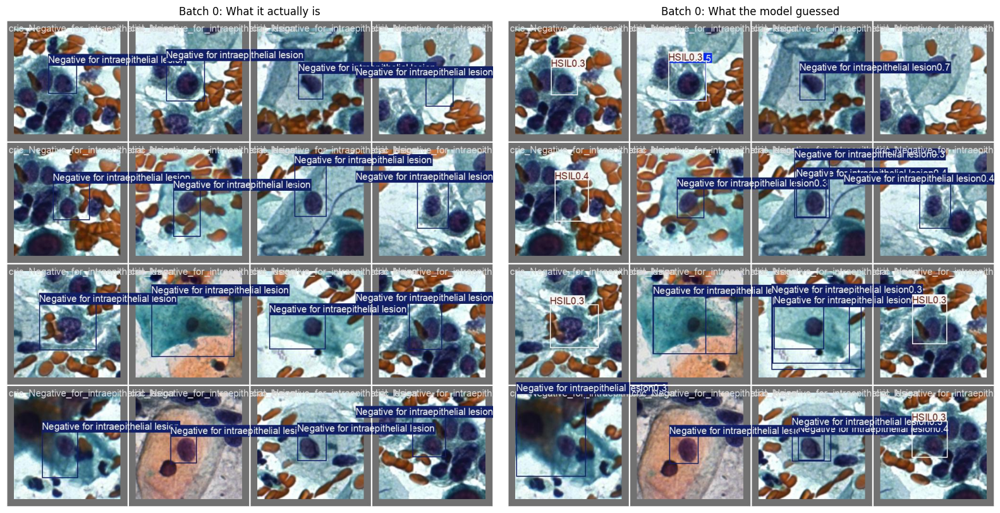

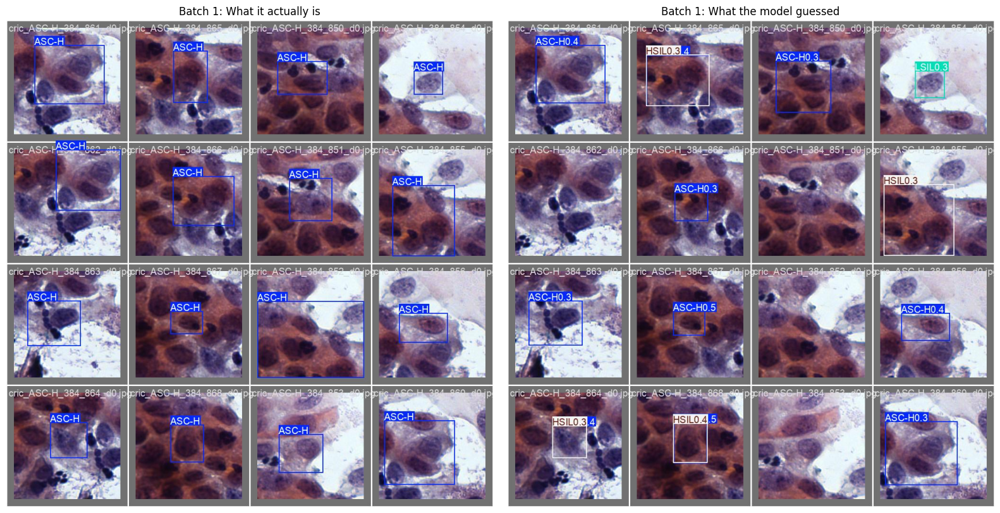

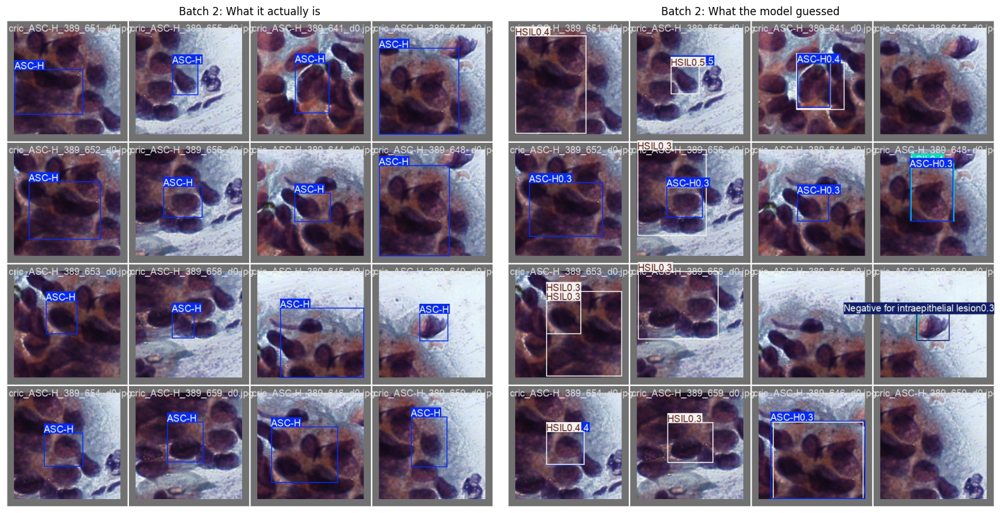

In [13]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

for i in range(3):
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    truth = mpimg.imread(f"/kaggle/working/runs/stage2_severity/val_batch{i}_labels.jpg")
    pred = mpimg.imread(f"/kaggle/working/runs/stage2_severity/val_batch{i}_pred.jpg")
    axes[0].imshow(truth)
    axes[0].set_title(f"Batch {i}: What it actually is")
    axes[0].axis("off")
    axes[1].imshow(pred)
    axes[1].set_title(f"Batch {i}: What the model guessed")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

**Confirmed visually:** boxes land in the right place (the "find the cell" part
works), and common classes (Negative, HSIL) are labeled correctly. Both real SCC
examples in the sampled batch were missed -- labeled ASC-H/HSIL instead of SCC --
matching the near-zero SCC score above. The model hasn't seen enough real SCC examples
to learn what makes it distinct.

## 12. Trying to fix the rare-class blindness: oversampling

Duplicates SCC (8x) and ASC-US (2x) in the **training split only** -- never val/test,
since inflating those would fake the accuracy numbers rather than actually test
anything. This is the practical lever available here: Ultralytics doesn't expose a
simple per-class loss-weighting option for detection, and more epochs alone wouldn't
change the underlying 1:33 ratio of SCC to Negative examples. ASC-H may not improve
much from this even though it's also weak -- it's a genuinely ambiguous category by
Bethesda's own definition ("cannot exclude HSIL"), not purely a data-count problem.

In [14]:
oversample_factors = {"SCC": 8, "ASC-US": 2}

frames = [cric_boxes.copy()]
frames[0]["dup"] = 0

train_mask = cric_boxes["split"] == "train"
for label, factor in oversample_factors.items():
    extra = cric_boxes[train_mask & (cric_boxes["label"] == label)]
    for i in range(1, factor):
        dup = extra.copy()
        dup["dup"] = i
        frames.append(dup)

cric_boxes_oversampled = pd.concat(frames, ignore_index=True)
print(cric_boxes_oversampled[cric_boxes_oversampled["split"] == "train"]["label"].value_counts())

label
Negative for intraepithelial lesion    4839
LSIL                                   1079
HSIL                                    906
ASC-US                                  850
SCC                                     832
ASC-H                                   651
Name: count, dtype: int64


In [15]:
shutil.rmtree("/kaggle/working/yolo_cric", ignore_errors=True)
write_yolo_dataset(cric_boxes_oversampled, "/kaggle/working/yolo_cric", cric_class_to_id, "cric")

cric:   0%|          | 0/10013 [00:00<?, ?it/s]

cric: wrote 10013 images, skipped 0


In [16]:
EPOCHS = 30
pbar = tqdm(total=EPOCHS, desc="Stage 2 (oversampled)")

def on_epoch_end(trainer):
    pbar.update(1)

model = YOLO("/kaggle/working/runs/stage1_cellfinder/weights/best.pt")
model.add_callback("on_train_epoch_end", on_epoch_end)
model.train(
    data="/kaggle/working/cric.yaml",
    epochs=EPOCHS,
    imgsz=224,
    project="/kaggle/working/runs",
    name="stage2_severity_oversampled",
)

Stage 2 (oversampled):   0%|          | 0/30 [00:00<?, ?it/s]

Ultralytics 8.4.171 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/cric.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/stage1_cellfinder/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=stage2_severity_over

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f42f4bb500>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

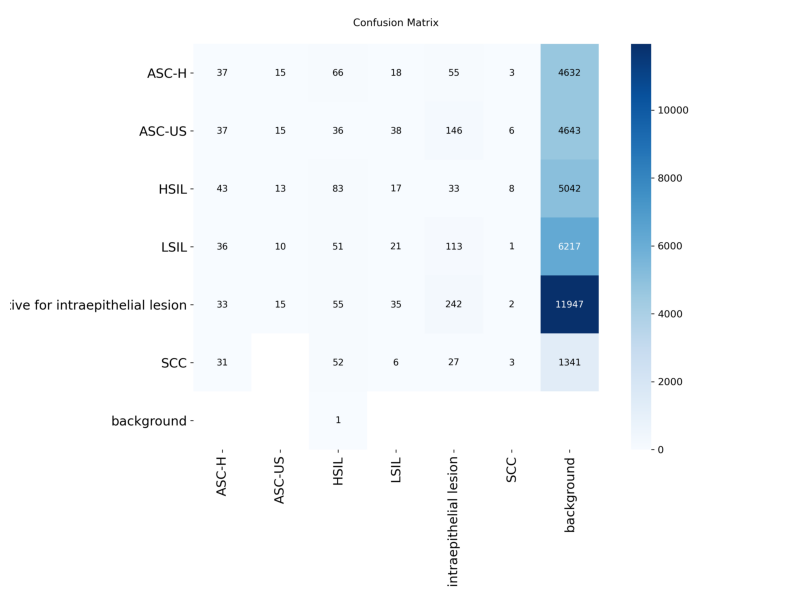

In [17]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("/kaggle/working/runs/stage2_severity_oversampled/confusion_matrix.png")
plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.axis("off")
plt.show()

### A note on reading mAP50-95

This metric is deliberately strict -- it checks box-overlap accuracy at ten
increasingly demanding thresholds (IoU 0.50 to 0.95) and averages them, unlike
plain accuracy or the looser mAP50. There's no fixed "good" number the way
there might be for classification accuracy, but for reference: YOLO11n (the
same model used here) scores around 0.39 mAP50-95 on COCO, the standard
80-class, ~118K-image benchmark, and even the best, largest detectors in the
world only reach about 0.50-0.55. So a well-performing detector in general
tops out around 0.5, and the numbers below (0.22 overall, 0.32-0.38 on the
best-represented classes) sit in a believable range given a far smaller, far
more imbalanced medical dataset -- not a sign something's broken.

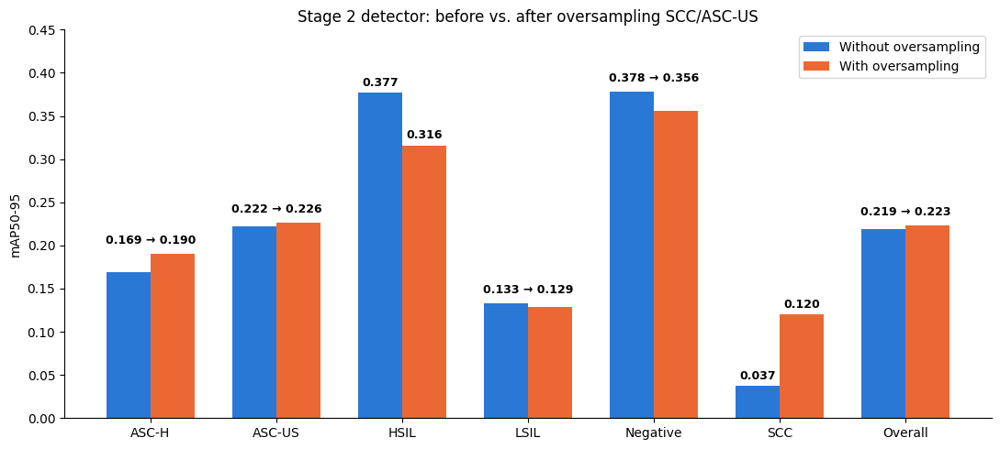

In [18]:
import matplotlib.pyplot as plt
import numpy as np

categories = ["ASC-H", "ASC-US", "HSIL", "LSIL", "Negative", "SCC", "Overall"]
before = [0.169, 0.222, 0.377, 0.133, 0.378, 0.037, 0.219]
after  = [0.190, 0.226, 0.316, 0.129, 0.356, 0.120, 0.223]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - width/2, before, width, label="Without oversampling", color="#2a78d6")
ax.bar(x + width/2, after, width, label="With oversampling", color="#eb6834")

ax.set_ylabel("mAP50-95")
ax.set_title("Stage 2 detector: before vs. after oversampling SCC/ASC-US")
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 0.45)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

# Only label the two classes with a real story (HSIL's drop, SCC's jump)
# individually -- the rest barely moved, so one combined label is clearer.
big_delta_classes = {"HSIL", "SCC"}
for i, cat in enumerate(categories):
    if cat in big_delta_classes:
        ax.text(x[i] - width/2, before[i] + 0.008, f"{before[i]:.3f}", ha="center", fontsize=9, fontweight="bold")
        ax.text(x[i] + width/2, after[i] + 0.008, f"{after[i]:.3f}", ha="center", fontsize=9, fontweight="bold")
    else:
        top = max(before[i], after[i])
        ax.text(x[i], top + 0.012, f"{before[i]:.3f} \u2192 {after[i]:.3f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("/kaggle/working/oversampling_comparison.png", dpi=150)
plt.show()

In [19]:
import shutil

shutil.copy2("/kaggle/working/runs/stage1_cellfinder/weights/best.pt",
             "/kaggle/working/stage1_cellfinder_best.pt")
shutil.copy2("/kaggle/working/runs/stage2_severity/weights/best.pt",
             "/kaggle/working/stage2_severity_best.pt")
shutil.copy2("/kaggle/working/runs/stage2_severity_oversampled/weights/best.pt",
             "/kaggle/working/stage2_severity_oversampled_best.pt")

print("Done -- three files now in /kaggle/working, ready to download individually.")

Done -- three files now in /kaggle/working, ready to download individually.


**Next:** compare this run's `results_dict` and per-class `maps` against stage 2's
original numbers above (especially SCC's mAP50-95, 0.054 before). Then either iterate
further on the rare-class problem, or accept this as the working detector and move on
to the Mendeley end-to-end pipeline test (run the detector on a Mendeley field image,
grade every detected cell, take the worst grade, compare to Mendeley's known label).